# TIRAVEL — building a template from the spectra themselves

UNICOR and TODCOR both need a template to correlate against. **TIRAVEL**
(Template-Independent RAdial VELocity; Zucker & Mazeh 2006,
[arXiv:astro-ph/0607293](https://arxiv.org/abs/astro-ph/0607293)) instead
*builds* one out of the observations. Given a set of trial radial velocities it
shifts every epoch to rest, measures how well the set then aligns (the scalar
`rho` in `[0, 1]`), and co-adds the epochs with maximum-likelihood weights into
a single template.

This notebook demonstrates that construction on HARPS spectra of **LTT 9779
(TOI-193)** — the quiet, slowly-rotating host of an ultra-hot Neptune
([Jenkins et al. 2020](https://arxiv.org/abs/2009.12832)). Because the star is
quiet and Sun-like, a PHOENIX **library template already fits it very well**, so
this is a *validation*: TIRAVEL should reconstruct, from the data alone, a
template that matches the library one and yields the same radial velocities.
Where TIRAVEL actually earns its keep is the opposite case — peculiar,
double-lined, or emission-line stars for which no good library model exists.

Two points to keep in mind:
- TIRAVEL velocities are **relative**: only their *differences* enter the
  alignment, so the template's rest frame inherits whatever zero point the
  input velocities carry.
- This is the **fixed-velocity** step — velocities in, template out. `rho` is
  exactly the objective a future optimizer would maximise over the velocities;
  here we evaluate it once, at a first UNICOR estimate.

## 1&nbsp;&nbsp;Setup

In [19]:
import numpy as np
import matplotlib.pyplot as plt

from sparta.Observations import Observations
from sparta.UNICOR.Spectrum import Spectrum
from sparta.UNICOR.Template import Template

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

## 2&nbsp;&nbsp;Load the HARPS observations

`Observations` reads a directory of visit FITS files into a `TimeSeries`. We
take a 5000 Å window (one echelle order after the DRS merge) and half the
available epochs (`sample_rate=2`), then run the standard preprocessing
(`SpecPreProccess`: trim, resample to a log-λ grid, de-cosmic, band-pass
filter, apodise).

In [20]:
obs_data = Observations(survey="HARPS", target_visits_lib="data/TOI193/",
                        min_wv=4990, max_wv=5090, sample_rate=2)
for spec in obs_data.time_series.vals:
    spec.SpecPreProccess()

n_epochs = len(obs_data.time_series.vals)
print(f"{n_epochs} epochs loaded, "
      f"spanning {np.ptp(obs_data.time_series.times):.1f} days.")

16 epochs loaded, spanning 53.1 days.


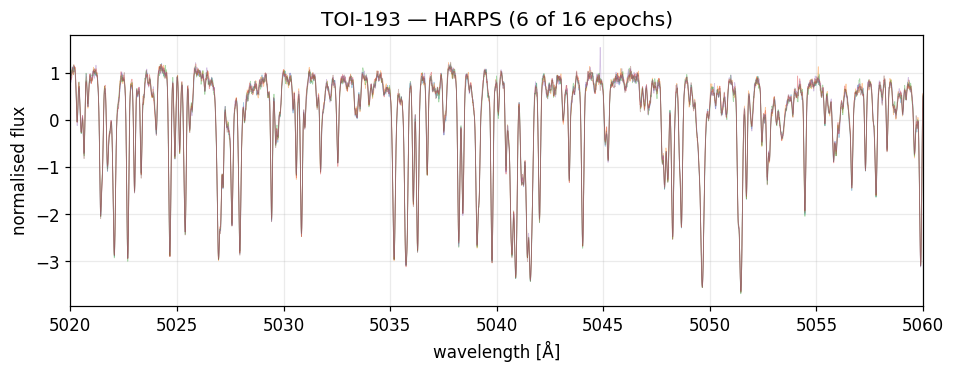

In [21]:
# A few individual epochs, with their median overplotted: the spectra are
# essentially identical frame to frame (a quiet star, tiny RV shifts).
fig, ax = plt.subplots(figsize=(10, 3.2))
for spec in obs_data.time_series.vals[:6]:
    ax.plot(spec.wv[0], spec.sp[0], lw=0.5, alpha=0.4)
ax.set(xlabel="wavelength [Å]", ylabel="normalised flux",
       title=f"TOI-193 — HARPS (6 of {n_epochs} epochs)", xlim=(5020, 5060))
plt.show()

## 3&nbsp;&nbsp;A library template and a first RV estimate (UNICOR)

We start from a PHOENIX synthetic spectrum at the published stellar parameters
(T = 5500 K, log g = 4.5, solar), broaden it for rotation (`vsini = 1.5` km/s)
and the HARPS instrumental profile (R = 115 000), and run it through the same
preprocessing as the data.

In [22]:
lib = Template(temp=5500, log_g=4.5, metal=0, alpha=0,
               min_val=4980, max_val=5100, air=False)
lib = Template(template=Spectrum(wv=lib.model.wv, sp=lib.model.sp).InterpolateSpectrum())
lib.RotationalBroadening(epsilon=0.5, vsini=1.5)
lib = Template(template=Spectrum(wv=lib.model.wv, sp=lib.model.sp).SpecPreProccess())
lib = Template(template=Spectrum(wv=lib.model.wv, sp=lib.model.sp).InterpolateSpectrum(delta=0.5))
lib.GaussianBroadening(resolution=115_000)
template_library = Template(template=Spectrum(wv=lib.model.wv, sp=lib.model.sp).SpecPreProccess())

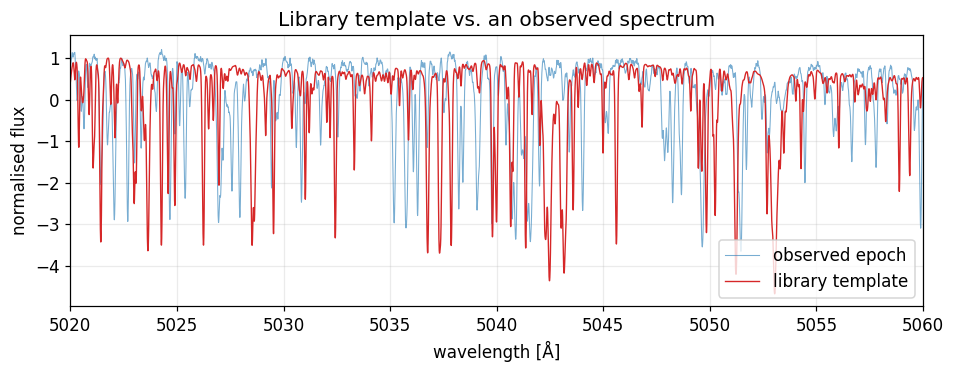

In [23]:
# The library template over a representative observed epoch.
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(obs_data.time_series.vals[0].wv[0], obs_data.time_series.vals[0].sp[0],
        lw=0.7, alpha=0.6, label="observed epoch")
ax.plot(template_library.model.wv[0], template_library.model.sp[0],
        lw=0.9, color="C3", label="library template")
ax.set(xlabel="wavelength [Å]", ylabel="normalised flux",
       title="Library template vs. an observed spectrum", xlim=(5020, 5060))
ax.legend(loc="lower right")
plt.show()

In [24]:
# UNICOR RVs of every epoch against the library template.
rv_library = obs_data.calc_rv_against_template(
    template_library, dv=0.1, VelBound=[-117, 117],
    combine_ccfs=False).vels

print(f"systemic RV ≈ {np.mean(rv_library):.3f} km/s, "
      f"scatter = {np.std(rv_library) * 1e3:.1f} m/s")

100%|██████████| 16/16 [00:00<00:00, 141.99it/s]

systemic RV ≈ -94.034 km/s, scatter = 14.6 m/s


The star sits near −94 km/s and the epoch-to-epoch scatter is only ~15 m/s —
the planet's reflex motion is close to this subset's noise floor. What matters
below is not the absolute RVs but whether TIRAVEL, given them, rebuilds the
same template.

## 4&nbsp;&nbsp;Build a template from the data with TIRAVEL

`build_tiravel_template` aligns the epochs at the UNICOR velocities, forms their
correlation matrix, and co-adds them with the leading-eigenvector weights.

In [25]:
obs_data.build_tiravel_template(rv_library)
tir = obs_data.tiravel                       # the TIRAVEL object
template_tiravel = obs_data.tiravel_template  # the co-added Template

print(f"alignment  rho = {tir.rho:.4f}   (1 = perfectly aligned)")
print(f"n_eff = {tir.diagnostics['n_eff']:.1f} of {n_epochs} epochs contribute")

alignment  rho = 0.9979   (1 = perfectly aligned)
n_eff = 16.0 of 16 epochs contribute


`rho = 0.998` says the de-shifted spectra are almost perfectly described by one
common component — as expected for a quiet star. The co-addition weights show
how much each epoch contributes; here they are near-uniform (`n_eff ≈ 16`), so
no single epoch dominates and none anti-correlates.

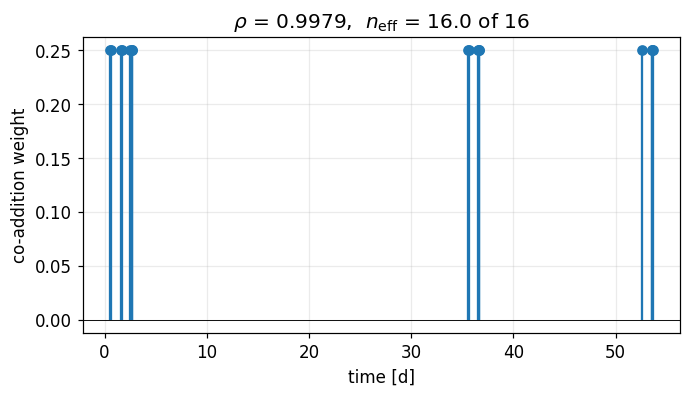

In [26]:
tir.plotWeights(times=obs_data.time_series.times)
plt.show()

## 5&nbsp;&nbsp;Does the data-driven template match the library one?

The two templates live on different grids and scales (the TIRAVEL template is a
co-addition of normalised residuals; the library one is continuum-normalised
and filtered), so we compare their **shapes**: interpolate both onto a common
window and standardise each to zero mean, unit variance.

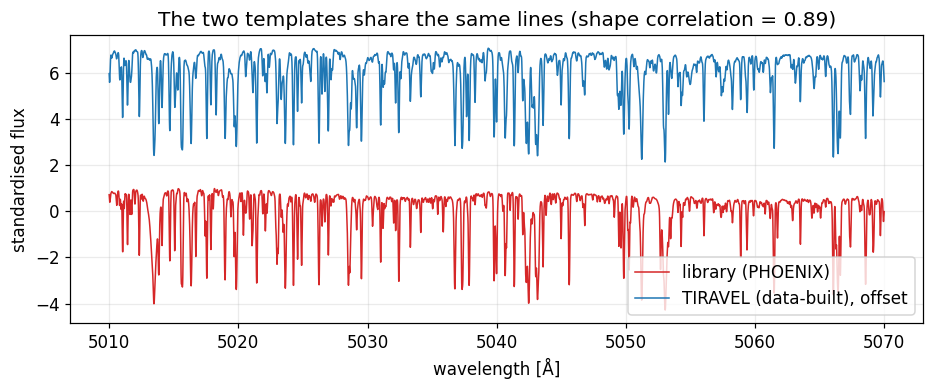

In [27]:
window = (5010, 5070)
grid = np.linspace(*window, 4000)
lib_line = np.interp(grid, template_library.model.wv[0], template_library.model.sp[0])
tir_line = np.interp(grid, template_tiravel.model.wv[0], template_tiravel.model.sp[0])
standardise = lambda x: (x - x.mean()) / x.std()
lib_z, tir_z = standardise(lib_line), standardise(tir_line)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(grid, lib_z, lw=1.0, color="C3", label="library (PHOENIX)")
ax.plot(grid, tir_z + 6, lw=1.0, color="C0", label="TIRAVEL (data-built), offset")
ax.set(xlabel="wavelength [Å]", ylabel="standardised flux",
       title=f"The two templates share the same lines "
             f"(shape correlation = {np.corrcoef(lib_z, tir_z)[0, 1]:.2f})")
ax.legend(loc="lower right")
plt.show()

The lines land in the same places with the same relative depths — TIRAVEL has
reconstructed the stellar spectrum from the observations alone, with no PHOENIX
model as input.

## 6&nbsp;&nbsp;Re-measured RVs

Finally, re-run UNICOR against the TIRAVEL template. Since it matches the
library template, the velocities should be essentially unchanged — the
consistency check that closes the loop.

100%|██████████| 16/16 [00:00<00:00, 165.47it/s]


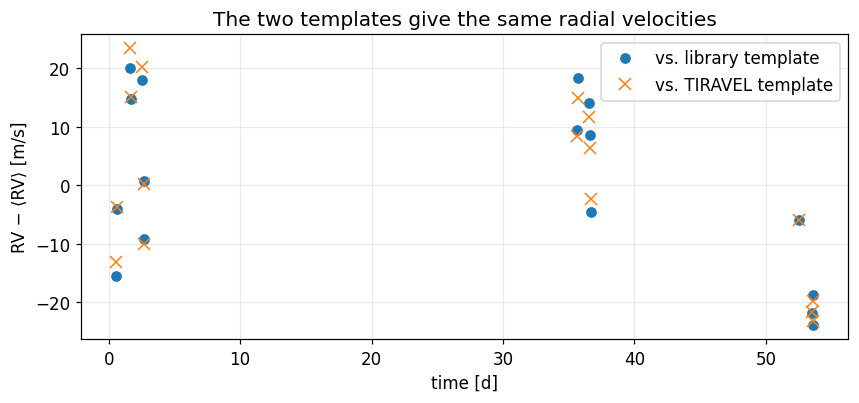

epoch-to-epoch RV difference (library vs TIRAVEL): 1.8 m/s rms


In [28]:
rv_tiravel = obs_data.calc_rv_against_template(
    template_tiravel, dv=0.1, VelBound=[-117, 117],
    combine_ccfs=False).vels

t = np.asarray(obs_data.time_series.times)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t, (rv_library - rv_library.mean()) * 1e3, "o", label="vs. library template")
ax.plot(t, (rv_tiravel - rv_tiravel.mean()) * 1e3, "x", ms=8, label="vs. TIRAVEL template")
ax.set(xlabel="time [d]", ylabel="RV − ⟨RV⟩ [m/s]",
       title="The two templates give the same radial velocities")
ax.legend(loc="upper right")
plt.show()

rms = np.std(rv_tiravel - rv_library) * 1e3
print(f"epoch-to-epoch RV difference (library vs TIRAVEL): {rms:.1f} m/s rms")

## Takeaway

On this quiet, Sun-like star the PHOENIX library template was already an
excellent match, so TIRAVEL simply **reproduced** it from the data (`rho =
0.998`, matching lines, RVs agreeing to a few m/s). That is the point of the
demonstration: it *validates* the template-construction machinery on a case
where the right answer is known.

The method becomes genuinely useful when a library template is *not* available
or *not* trustworthy — active, chemically peculiar, rapidly-rotating, or
double-lined stars — where a template built from the data itself is the only
faithful one. And because `rho` is a scalar that peaks when the input velocities
are correct, it is the natural objective for optimising the velocities
themselves; that step (turning TIRAVEL from a template builder into a full
RV estimator) is the planned next addition.